# Pre-research: Estimate optimal hyperparameters and choose hyperparameter search intervals around optimum

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme()

## Simpson 1-tpe_suggest-optimal_hp-split: Vary optimizers and their common params

### Evaluate HOpt results

In [3]:
omniopt_results_df = pd.read_csv("../data/1_tpe_suggest_optimal_hp_split/omniopt_results.csv")
omniopt_results_df

,Unnamed: 0,time,ExperimentConfig.lr,ExperimentConfig.lr_decay,ExperimentConfig.momentum,ExperimentConfig.num_epochs,ExperimentConfig.optimizer,ExperimentConfig.weight_decay,RESULT,endtime,hostname,logfile_path,loss,starttime,omniopt_seed
0,0,2022-10-03 20:26:19,0.009828,1.081387e-05,0.687773,44.0,Adam,0.070611,0.903133,1.664829e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.903133,1.664829e+09,1
1,1,2022-10-03 20:26:20,0.000258,9.404205e-06,0.731779,52.0,SGD,0.003305,0.940199,1.664829e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.940199,1.664829e+09,1
2,2,2022-10-03 20:26:25,0.011272,1.061262e-06,0.971659,86.0,Adamax,0.024168,0.829767,1.664829e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.829767,1.664829e+09,1
3,3,2022-10-03 20:26:31,0.000097,9.154823e-07,0.689407,39.0,Adamax,0.001301,0.855942,1.664829e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.855942,1.664829e+09,1
4,4,2022-10-03 20:26:35,0.024008,1.043677e-07,0.983237,56.0,Adam,0.059533,0.904089,1.664829e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.904089,1.664829e+09,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
994,994,2022-10-04 03:54:52,0.001891,7.048078e-07,0.619724,57.0,Adamax,0.005717,0.633741,1.664856e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.633741,1.664856e+09,1
995,995,2022-10-04 03:55:51,0.000604,8.360108e-07,0.543989,86.0,AdamW,0.011151,0.366641,1.664856e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.366641,1.664856e+09,1
996,996,2022-10-04 03:56:07,0.000759,2.851222e-06,0.573521,88.0,SGD,0.008548,0.901414,1.664856e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.901414,1.664856e+09,1
997,997,2022-10-04 03:56:42,0.003332,5.987593e-07,0.629919,87.0,AdamW,0.045566,0.815820,1.664856e+09,taurusi8004,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.815820,1.664856e+09,1


In [19]:
omniopt_results_df.groupby(by="ExperimentConfig.optimizer").min()["RESULT"].sort_values()

ExperimentConfig.optimizer
AdamW      0.297478
Adam       0.362820
Adamax     0.405426
RMSprop    0.429690
Adagrad    0.564578
SGD        0.734047
Name: RESULT, dtype: float64

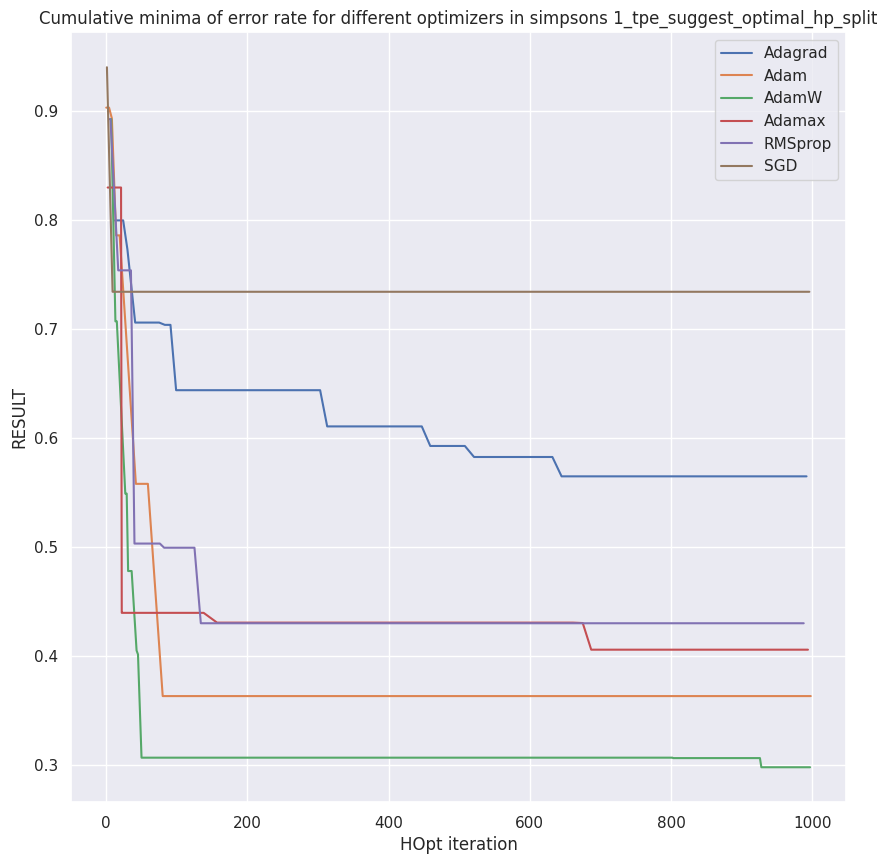

In [21]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_xlabel("HOpt iteration")
ax.set_title("Cumulative minima of error rate for different optimizers in simpsons 1_tpe_suggest_optimal_hp_split")

for optimizer, group_df in omniopt_results_df.groupby(by="ExperimentConfig.optimizer"):
    sns.lineplot(x=group_df.index, y=np.minimum.accumulate(group_df["RESULT"]), ax=ax, label=optimizer)

## Simpson 2-tpe_suggest-optimal_hp-SGD: vary hyperparams for SGD separately

In [22]:
omniopt_results_2_df = pd.read_csv("../data/2_tpe_suggest_optimal_hp_SGD/omniopt_results.csv")
omniopt_results_2_df

,Unnamed: 0,time,ExperimentConfig.lr,ExperimentConfig.lrs_gamma,ExperimentConfig.momentum,ExperimentConfig.num_epochs,ExperimentConfig.weight_decay,RESULT,endtime,hostname,logfile_path,loss,starttime,omniopt_seed
0,0,2022-10-04 15:51:05,0.023070,0.999553,0.614603,42.0,0.082957,0.777035,1.664899e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.777035,1.664899e+09,1
1,1,2022-10-04 15:51:05,0.003979,0.999631,0.612837,66.0,0.022942,0.618265,1.664899e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.618265,1.664899e+09,1
2,2,2022-10-04 15:51:11,0.003100,0.994338,0.979366,71.0,0.000181,0.260413,1.664899e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.260413,1.664899e+09,1
3,3,2022-10-04 15:51:16,0.002844,0.999705,0.577077,33.0,0.006045,0.806840,1.664899e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.806840,1.664899e+09,1
4,4,2022-10-04 15:51:21,0.002198,0.999518,0.540199,50.0,0.001455,0.815055,1.664899e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.815055,1.664899e+09,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1494,1494,2022-10-05 00:34:46,0.080644,0.999400,0.982328,63.0,0.000239,0.892625,1.664930e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.892625,1.664930e+09,1
1495,1495,2022-10-05 00:34:52,0.002524,0.999631,0.933630,70.0,0.000132,0.317730,1.664930e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.317730,1.664930e+09,1
1496,1496,2022-10-05 00:35:11,0.200321,0.999518,0.970318,77.0,0.000394,0.892625,1.664930e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.892625,1.664930e+09,1
1497,1497,2022-10-05 00:35:28,0.027927,0.992185,0.928503,72.0,0.000159,0.225449,1.664930e+09,taurusi8021,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.225449,1.664930e+09,1


In [28]:
omniopt_results_2_df.iloc[omniopt_results_2_df["RESULT"].argmin()]

Unnamed: 0                                                                     650
time                                                           2022-10-04 19:31:20
ExperimentConfig.lr                                                       0.084135
ExperimentConfig.lrs_gamma                                                0.963482
ExperimentConfig.momentum                                                 0.960285
ExperimentConfig.num_epochs                                                   79.0
ExperimentConfig.weight_decay                                             0.000225
RESULT                                                                    0.196981
endtime                                                          1664911991.263067
hostname                                                               taurusi8021
logfile_path                     /beegfs/.global0/ws/clehm-machine-learning-pro...
loss                                                                      0.196981
star

<Axes: ylabel='RESULT'>

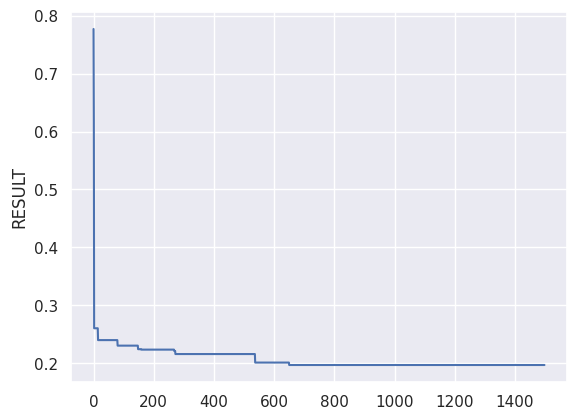

In [25]:
sns.lineplot(x=omniopt_results_2_df.index, y=np.minimum.accumulate(omniopt_results_2_df["RESULT"]))

## Simpson 3_tpe_suggest_optimal_hp_AdamW: vary hyperparams for AdamW separately

In [26]:
omniopt_results_3_df = pd.read_csv("../data/3_tpe_suggest_optimal_hp_AdamW/omniopt_results.csv")
omniopt_results_3_df

,Unnamed: 0,time,ExperimentConfig.lr,ExperimentConfig.num_epochs,ExperimentConfig.weight_decay,RESULT,endtime,hostname,logfile_path,loss,starttime,omniopt_seed
0,0,2022-10-04 15:49:06,0.309592,44.0,0.010803,0.892625,1.664899e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.892625,1.664899e+09,1
1,1,2022-10-04 15:49:09,0.000105,53.0,0.005460,0.293848,1.664899e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.293848,1.664899e+09,1
2,2,2022-10-04 15:49:15,0.003979,77.0,0.000495,0.317539,1.664899e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.317539,1.664899e+09,1
3,3,2022-10-04 15:49:20,0.000100,79.0,0.064660,0.263088,1.664899e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.263088,1.664899e+09,1
4,4,2022-10-04 15:49:25,0.000087,89.0,0.002320,0.265380,1.664899e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.265380,1.664899e+09,1
...,...,...,...,...,...,...,...,...,...,...,...,...
1494,1494,2022-10-05 02:04:07,0.003479,73.0,0.001297,0.892625,1.664936e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.892625,1.664935e+09,1
1495,1495,2022-10-05 02:04:32,0.002584,77.0,0.001063,0.215514,1.664936e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.215514,1.664935e+09,1
1496,1496,2022-10-05 02:04:51,0.001660,80.0,0.000605,0.190867,1.664936e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.190867,1.664935e+09,1
1497,1497,2022-10-05 02:05:22,0.004924,75.0,0.000717,0.892625,1.664936e+09,taurusi8008,/beegfs/.global0/ws/clehm-machine-learning-pro...,0.892625,1.664936e+09,1


In [27]:
omniopt_results_3_df.iloc[omniopt_results_3_df["RESULT"].argmin()]

Unnamed: 0                                                                     588
time                                                           2022-10-04 19:42:16
ExperimentConfig.lr                                                       0.001602
ExperimentConfig.num_epochs                                                   85.0
ExperimentConfig.weight_decay                                             0.000612
RESULT                                                                    0.159534
endtime                                                          1664912665.471355
hostname                                                               taurusi8008
logfile_path                     /beegfs/.global0/ws/clehm-machine-learning-pro...
loss                                                                      0.159534
starttime                                                        1664912537.003016
omniopt_seed                                                                     1
Name

<Axes: ylabel='RESULT'>

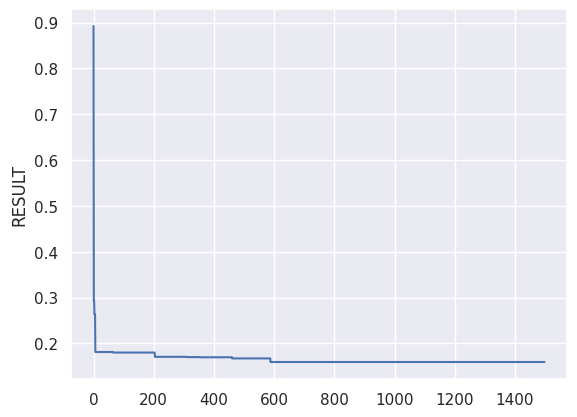

In [29]:
sns.lineplot(x=omniopt_results_3_df.index, y=np.minimum.accumulate(omniopt_results_3_df["RESULT"]))

## Compare SGD vs AdamW

<Axes: xlabel='HOpt iteration', ylabel='RESULT'>

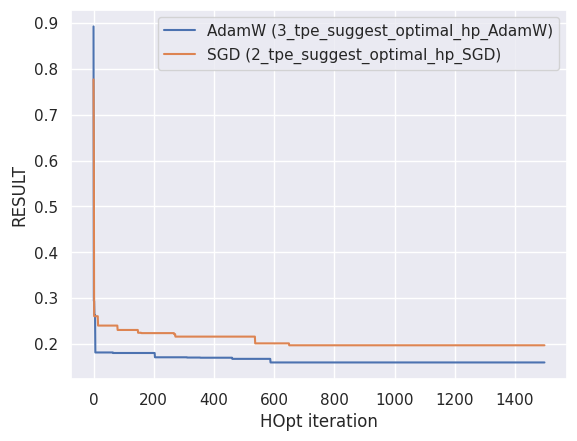

In [31]:
fig, ax = plt.subplots()
ax.set_xlabel("HOpt iteration")
sns.lineplot(x=omniopt_results_3_df.index, y=np.minimum.accumulate(omniopt_results_3_df["RESULT"]), ax=ax,
             label="AdamW (3_tpe_suggest_optimal_hp_AdamW)")
sns.lineplot(x=omniopt_results_2_df.index, y=np.minimum.accumulate(omniopt_results_2_df["RESULT"]), ax=ax,
             label="SGD (2_tpe_suggest_optimal_hp_SGD)")

### Difference between SGD and AdamW:

In [32]:
omniopt_results_2_df["RESULT"].min() - omniopt_results_3_df["RESULT"].min()

0.037447458922430205

=> AdamW outperforms SGD on 3% after ~700 iterations